<a href="https://colab.research.google.com/github/Simranpande/remedy-myth-checker/blob/main/remedy_myth_checker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd

# Try to load the dataset, skipping bad lines that contain extra commas
try:
    df = pd.read_csv("/content/remedies_data.csv", on_bad_lines='skip')
    print(f"Dataset successfully loaded with {len(df)} rows! (Some malformed rows may have been skipped)")
    display(df.head(3))
except Exception as e:
    print("Error loading dataset:", e)


Dataset successfully loaded with 4 rows! (Some malformed rows may have been skipped)


,remedy_id,remedy_name,target_symptom,traditional_claim,scientific_consensus,pros,cons,myth_status
0,1,Turmeric and Black Pepper,Joint Pain & Inflammation,Reduces arthritis pain and body inflammation,Curcumin in turmeric has strong anti-inflammat...,Natural anti-inflammatory; antioxidant-rich; s...,Low bioavailability without black pepper; high...,Validated
1,6,Aloe Vera Gel,Minor Burns & Sunburn,Heals first-degree burns and skin irritation f...,Contains glucomannan and gibberellins that sti...,Cooling relief; speeds up healing for minor su...,Oral consumption of aloe latex acts as a harsh...,Validated
2,9,Peppermint Oil,Tension Headaches & IBS,Relieves headaches when applied to temples and...,Menthol triggers cold-sensitive receptors (TRP...,Effective topical cooling relief; strong clini...,Can trigger severe acid reflux (GERD) if taken...,Validated


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Combine text columns to create a rich searchable corpus
df['combined_text'] = (
    df['remedy_name'].fillna('') + " " +
    df['target_symptom'].fillna('') + " " +
    df['traditional_claim'].fillna('')
)

# Initialize TF-IDF Vectorizer
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(df['combined_text'])

def search_remedy(user_query):
    # Transform query and compute similarity
    query_vec = vectorizer.transform([user_query])
    similarities = cosine_similarity(query_vec, tfidf_matrix).flatten()

    # Find the best match
    best_idx = similarities.argmax()
    best_score = similarities[best_idx]

    if best_score < 0.05:
        return "No close scientific match found. Try searching for symptoms like 'nausea' or ingredients like 'turmeric'."

    match = df.iloc[best_idx]

    # Print out formatted results
    print(f"🌿 Remedy Found: {match['remedy_name']}")
    print(f"🎯 Target Symptom: {match['target_symptom']}")
    print(f"💬 Traditional Claim: {match['traditional_claim']}")
    print(f"🔬 Scientific Consensus: {match['scientific_consensus']}")
    print(f"✅ Pros: {match['pros']}")
    print(f"⚠️ Cons / Risks: {match['cons']}")
    print(f"📌 Scientific Verdict: {match['myth_status']}")
    print(f"📊 Match Confidence: {round(best_score * 100, 1)}%\n" + "-"*50)

# Test your model right here in Colab!
search_remedy("I have a bad throat and cough")
search_remedy("Does putting butter on burns work?")

🌿 Remedy Found: Aloe Vera Gel
🎯 Target Symptom: Minor Burns & Sunburn
💬 Traditional Claim: Heals first-degree burns and skin irritation faster
🔬 Scientific Consensus: Contains glucomannan and gibberellins that stimulate collagen synthesis and skin regeneration.
✅ Pros: Cooling relief; speeds up healing for minor superficial burns.
⚠️ Cons / Risks: Oral consumption of aloe latex acts as a harsh laxative; rare topical allergic reactions.
📌 Scientific Verdict: Validated
📊 Match Confidence: 53.5%
--------------------------------------------------


/tmp/ipykernel_1441/3770576393.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='myth_status', palette='Set2')


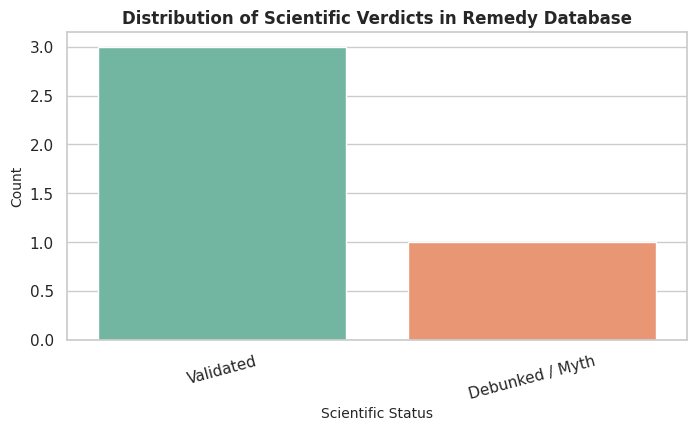

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 4))

# Count plot for myth statuses
ax = sns.countplot(data=df, x='myth_status', palette='Set2')
plt.title("Distribution of Scientific Verdicts in Remedy Database", fontsize=12, fontweight='bold')
plt.xlabel("Scientific Status", fontsize=10)
plt.ylabel("Count", fontsize=10)

plt.xticks(rotation=15)
plt.show()